In [ ]:
import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt

In [ ]:
integer = torch.tensor(1234)
double = torch.tensor(3.14159265359)

print(f"integer is a {integer.ndim}-d Tensor: {integer}")
print(f"Decimal is a {double.ndim}-d Tensor: {double}")

integer is a 0-d Tensor: 1234
Decimal is a 0-d Tensor: 3.1415927410125732


In [ ]:
fibonacci = torch.tensor([1,1,2,3,5,8,13,21,34,55])
count_to_100 = torch.tensor(range(100))

print(f"fibonacci is a {fibonacci.ndim}-d Tensor: {fibonacci.shape}")
print(f"count to 100 is a {count_to_100.ndim}-d Tensor: {count_to_100.shape}")

fibonacci is a 1-d Tensor: torch.Size([10])
count to 100 is a 1-d Tensor: torch.Size([100])


In [ ]:
matrix = torch.tensor([[1.0, 2.0, 3.0, 4.0], [5.0, 6.0, 7.0, 8.0]])
assert isinstance(matrix, torch.Tensor)
assert matrix.ndim == 2
images = torch.zeros(10,3,256,256)
assert isinstance(images, torch.Tensor)
assert images.ndim == 4
assert images.shape == (10,3,256,256)


In [ ]:
row_vector = matrix[1]
column_vector = matrix[:,1]
scalar = matrix[0,1]

In [ ]:
def func(a,b):
  c = torch.add(a,b)
  d = torch.subtract(b,1)
  e = torch.multiply(c,d)
  return e

In [ ]:
a,b = 2.5,4.5
e_out = func(a,b)
print(f"result of making tenosr function {e_out}")

result of making tenosr function 24.5


In [ ]:
class OurDenseLayer(torch.nn.Module):
  def __init__(self, num_inputs, num_outputs):
    super(OurDenseLayer,self).__init__()
    self.w = torch.nn.Parameter(torch.randn(num_inputs,num_outputs))
    self.bias = torch.nn.Parameter(torch.randn(num_outputs))
  def forward(self,x):
    z = torch.matmul(x,self.w) + self.bias
    y = torch.sigmoid(z)
    return y

In [ ]:
num_inputs = 2
num_outputs = 3
layer = OurDenseLayer(num_inputs, num_outputs)
x_input = torch.tensor([[1, 2.]])
y = layer(x_input)

In [ ]:
n_input_nodes = 2
n_output_nodes = 3

model = nn.Sequential(
    nn.Linear(n_input_nodes,n_output_nodes),
    nn.Sigmoid()
)

In [ ]:
x_input = torch.Tensor([[1,2.0]])
model_output = model(x_input)

In [ ]:
class LinearWithSigmoidActivation(nn.Module):
  def __init__(self, num_inputs, num_outputs):
    super(LinearWithSigmoidActivation,self).__init__()
    self.linear = nn.Linear(num_inputs,num_outputs)
    self.activation = nn.Sigmoid()
  def forward(self,inputs):
    linear_input = self.linear(inputs)
    output = self.activation(linear_input)
    return output

In [ ]:
n_input_nodes = 2
n_output_nodes = 3
model = LinearWithSigmoidActivation(n_input_nodes, n_output_nodes)
x_input = torch.tensor([[1, 2.0]])
y = model(x_input)

In [ ]:
class LinearButSometimesIdentity(nn.Module):
    def __init__(self, num_inputs, num_outputs):
        super(LinearButSometimesIdentity, self).__init__()
        self.linear = nn.Linear(num_inputs, num_outputs)

    def forward(self,inputs,isidentity=False):
        if isidentity:
          return inputs
        else:
          linear_input = self.linear(inputs)
          return linear_input


In [ ]:
num_inputs = 2
num_outputs = 3
model = LinearButSometimesIdentity(num_inputs, num_outputs)
x_input = torch.tensor([[1, 2.0]])

out_with_linear = model(x_input)

out_with_identity = model(x_input, isidentity=True)

print(f"output with linear: {out_with_linear}")
print(f"output with identity: {out_with_identity}")

output with linear: tensor([[-0.5356, -0.3332,  1.5596]], grad_fn=<AddmmBackward0>)
output with identity: tensor([[1., 2.]])


In [ ]:
x = torch.tensor(3.0,requires_grad=True)
y = x ** 2
y.backward()

dy_dx = x.grad

assert dy_dx == 6.0

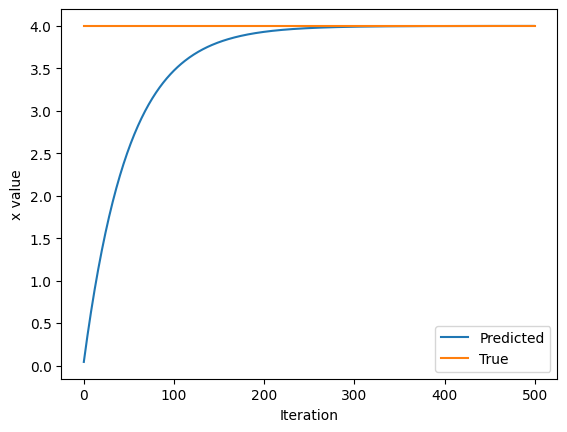

In [ ]:
x = torch.randn(1)

learning_rate = 1e-2
history = []
x_f = 4

for i in range(500):
  x = torch.tensor([x],requires_grad=True)
  loss = (x-x_f)**2
  loss.backward()

  x = x.item() - learning_rate * x.grad
  history.append(x.item())

plt.plot(history)
plt.plot([0, 500], [x_f, x_f])
plt.legend(('Predicted', 'True'))
plt.xlabel('Iteration')
plt.ylabel('x value')
plt.show()

